# Gaussian process regression: molten-salt corrosion

This notebook implements the GPR section of the corrosion study. It gives preliminary
verification. It does not give a final model comparison.

The notebook reads the cleaned dataset from `data/processed/corrosion_data_clean.parquet`.
The notebook `notebooks/data_cleaning.ipynb` produced this file. Other notebooks in this
project use the same file.

Limits of this work:

- The temperature value 4,765 °C needs a source review. The notebook keeps this value.
- The `log1p` target is a provisional choice. This notebook does not compare target modes.
- Random row folds mix sample types. The results are not a test on unknown alloys.

The notebook writes outputs to `notebooks/gpr_outputs/`. Run all cells with the project
environment. Run `uv sync` first. Then select the `.venv` kernel. The dependencies are in
`uv.lock`.

In [1]:
import hashlib
import json
import platform
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from matplotlib.lines import Line2D
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, WhiteKernel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
TARGET_MODE = "log1p"   # 'raw' is also supported; choose before evaluating the outer folds.
RUN_MIXED_CV = True
RUN_ALLOY_CV = True
N_ALLOY_HOLDOUTS = 3
OUTER_FOLDS = 5
INNER_FOLDS = 3

for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "pyproject.toml").is_file():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the project root with pyproject.toml")

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "corrosion_data_clean.parquet"
OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "gpr_outputs"

TARGET = "corrosion_rate_um_per_year"
CONDITIONS = ["temperature_c", "exposure_time_h", "flow_m_per_s"]
HEADGAS = ["headgas_air", "headgas_n2", "headgas_o2_sealed_loop"]
ELEMENTS = [
    "ni_wt_pct", "cr_wt_pct", "fe_wt_pct", "c_wt_pct", "mn_wt_pct", "si_wt_pct",
    "n_wt_pct", "nb_wt_pct", "co_wt_pct", "mo_wt_pct", "al_wt_pct", "ti_wt_pct",
    "cu_wt_pct", "w_wt_pct", "p_wt_pct", "s_wt_pct",
]
FEATURES = CONDITIONS + HEADGAS + ELEMENTS

plt.rcParams.update({
    "figure.figsize": (6.4, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print("Environment:", {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "sklearn": sklearn.__version__,
})
print("Data file:", DATA_PATH, "exists:", DATA_PATH.is_file())

Environment: {'python': '3.13.0', 'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'sklearn': '1.9.1'}
Data file: D:\Documents\Coding Projects\molten_salt\data\processed\corrosion_data_clean.parquet exists: True


In [ ]:
def load_data() -> pd.DataFrame:
    """Load the parquet produced by notebooks/data_cleaning.ipynb and validate it."""
    if not DATA_PATH.is_file():
        raise FileNotFoundError(
            f"Clean data not found at {DATA_PATH}. Run notebooks/data_cleaning.ipynb first."
        )
    raw_bytes = DATA_PATH.read_bytes()
    data = pd.read_parquet(DATA_PATH)
    data = data.sort_values(
        ["paper_id", "alloy", "temperature_c", "exposure_time_h", "flow_m_per_s", TARGET],
        kind="stable",
    ).reset_index(drop=True)

    required = FEATURES + [TARGET, "paper_id", "alloy"]
    missing = set(required) - set(data.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    numeric = data.astype({column: "float64" for column in required if column not in {"paper_id", "alloy"}})
    if numeric[required].isna().any().any():
        raise ValueError("Missing required values; run the cleaning notebook first.")
    if not np.isfinite(numeric[FEATURES + [TARGET]].to_numpy(dtype=float)).all():
        raise ValueError("Nonfinite numerical values.")
    if (numeric[TARGET] < 0).any():
        raise ValueError("Negative corrosion rates require review.")
    if not numeric[ELEMENTS].sum(axis=1).between(95, 105).all():
        raise ValueError("Composition totals outside the cleaning tolerance.")
    if not numeric[ELEMENTS].ge(0).all().all() or not numeric[ELEMENTS].le(100).all().all():
        raise ValueError("Invalid elemental percentages.")
    if not numeric[HEADGAS].isin([0, 1]).all().all() or not numeric[HEADGAS].sum(axis=1).eq(1).all():
        raise ValueError("Invalid one-hot headgas columns.")

    data[TARGET] = data[TARGET].astype(float)
    for column in CONDITIONS + ELEMENTS:
        data[column] = data[column].astype(float)
    for column in HEADGAS:
        data[column] = data[column].astype(int)
    data.attrs["source"] = str(DATA_PATH)
    data.attrs["sha256"] = hashlib.sha256(raw_bytes).hexdigest()
    return data


data = load_data()
X, y = data[FEATURES].copy(), data[TARGET].copy()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Data:",
      {"source": data.attrs["source"],"sha256": data.attrs["sha256"][:16] + "..."},
      "shape:", data.shape, "predictors:", X.shape[1])
print("Repeated predictor rows:", X.duplicated(keep=False).sum())

Data: {'source': 'D:\\Documents\\Coding Projects\\molten_salt\\data\\processed\\corrosion_data_clean.parquet', 'sha256': '3c71fca7ed7f6f0b...'} shape: (109, 25) predictors: 22
Repeated predictor rows: 6


## 1. Data audit

The cleaning notebook approximates some raw values. It converts composition limits to the
stated bounds. It converts ranges to midpoints. It converts `<` corrosion rates to the stated
numerical limit. These values are inherited approximations. They are not new measurements.
The salt is constant (0.40 KNO3 + 0.60 NaNO3). The notebook uses only the included columns.
The identifiers `paper_id` and `alloy` are metadata only.

Warning: the entry 4765 °C is not a possible test temperature. Do not replace this value
with a guess. The notebook keeps the entry and exports it for review.

Note: some rows have the same predictor vector with different corrosion rates. The notebook
keeps these rows. Random splitting can then put related rows on both sides of a fold.

In [3]:
audit = data.loc[data.temperature_c > 1000].copy()
audit.to_csv(OUTPUT_DIR / "temperature_review.csv", index_label="source_row")
print("Temperature rows requiring source review:")
print(audit[["paper_id", "alloy", "temperature_c"]].to_string())

Temperature rows requiring source review:
   paper_id                     alloy  temperature_c
59     P008  Type 316 Stainless Steel         4765.0


### Figure: dataset overview

These plots show the structure of the dataset. The left plot shows corrosion rate against
temperature. One point at 4765 °C is visible and needs review. The middle plot shows
corrosion rate against exposure time. The right plot shows the target distribution in
`log1p` space.

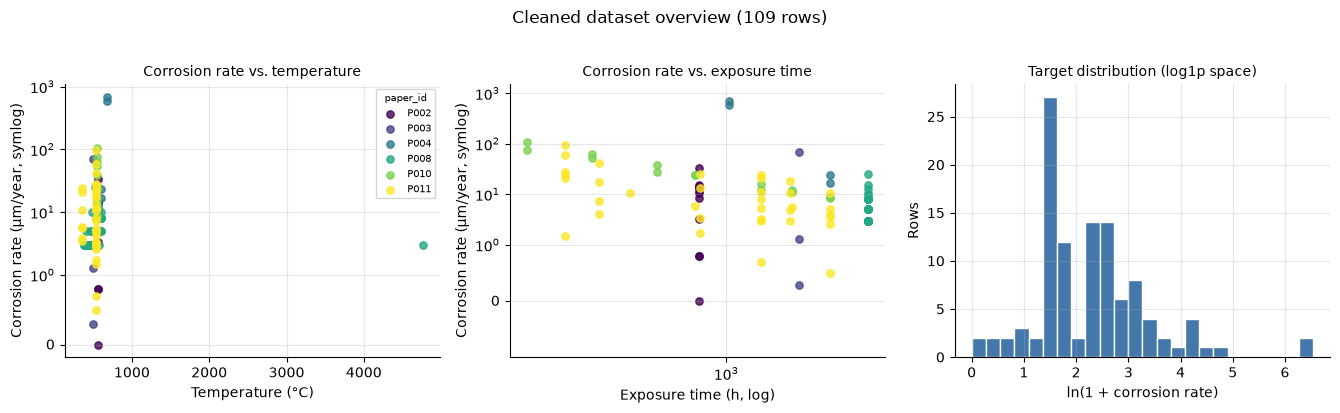

In [4]:
# Dataset overview: where the observations live, and how the target behaves with conditions.
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))

papers = sorted(data.paper_id.unique())
cmap = plt.colormaps["viridis"].resampled(len(papers))
paper_color = {name: cmap(i) for i, name in enumerate(papers)}
for paper, group in data.groupby("paper_id"):
    axes[0].scatter(group.temperature_c, group[TARGET], s=28, alpha=0.8,
                    color=paper_color[paper], label=paper)
axes[0].set_yscale("symlog", linthresh=1)
axes[0].set(xlabel="Temperature (°C)", ylabel="Corrosion rate (μm/year, symlog)")
axes[0].set_title("Corrosion rate vs. temperature", fontsize=10)
axes[0].legend(fontsize=7, title="paper_id", title_fontsize=7, loc="best")

for paper, group in data.groupby("paper_id"):
    axes[1].scatter(group.exposure_time_h, group[TARGET], s=28, alpha=0.8,
                    color=paper_color[paper])
axes[1].set_xscale("log")
axes[1].xaxis.set_major_locator(plt.matplotlib.ticker.LogLocator(base=10, numticks=6))
axes[1].xaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
axes[1].set_yscale("symlog", linthresh=1)
axes[1].set_ylim(-1, 1500)
axes[1].set(xlabel="Exposure time (h, log)", ylabel="Corrosion rate (μm/year, symlog)")
axes[1].set_title("Corrosion rate vs. exposure time", fontsize=10)

axes[2].hist(np.log1p(data[TARGET]), bins=24, color="#4477aa", edgecolor="white")
axes[2].set(xlabel="ln(1 + corrosion rate)", ylabel="Rows")
axes[2].set_title("Target distribution (log1p space)", fontsize=10)

fig.suptitle("Cleaned dataset overview (109 rows)", y=1.02, fontsize=12)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "data_overview.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. Preprocessing and model

The pipeline changes the data inside each training fold:

- It scales the condition variables (temperature, time, flow) with `StandardScaler`.
- It divides each elemental wt.% value by 100.
- It keeps the gas indicators as 0/1 values.

The GP uses an isotropic RBF or Matern kernel, a trainable amplitude, and a WhiteKernel for
observation noise. The value `alpha=1e-8` stabilizes the covariance. The optimization uses
L-BFGS-B with the log marginal likelihood as the objective.

The grid has nine candidates. Each candidate is RBF, Matern ν=1.5, or Matern ν=2.5, with an
initial length scale of 0.1, 1, or 10. The grid gives start points only. The optimizer finds
the final values in each fit. The bounds are: amplitude 1e-3 to 1e3, length scale 1e-2 to
1e2, noise variance 1e-6 to 1e1. `normalize_y=True` centers and scales the training target.

The default target is ln(1+y). The inverse transform gives a median on the original scale.
The notebook uses this median for all scores. It does not clip negative predictions. A raw
target mode exists, but this notebook does not compare the two modes.

In [5]:
KERNEL_BASE_NAMES = ["RBF", "Matern(nu=1.5)", "Matern(nu=2.5)"]
KERNEL_LENGTH_INITS = [0.1, 1.0, 10.0]


def divide_by_100(values):
    return np.asarray(values, dtype=float) / 100.0


def kernel_candidates():
    return [ConstantKernel(1.0, (1e-3, 1e3)) * base + WhiteKernel(0.1, (1e-6, 1e1))
            for length in KERNEL_LENGTH_INITS
            for base in [RBF(length, (1e-2, 1e2)),
                         Matern(length, (1e-2, 1e2), nu=1.5),
                         Matern(length, (1e-2, 1e2), nu=2.5)]]


def build_model(target_mode):
    if target_mode not in {"raw", "log1p"}:
        raise ValueError("Choose raw or log1p.")
    preprocess = ColumnTransformer([
        ("conditions", StandardScaler(), CONDITIONS),
        ("composition", FunctionTransformer(divide_by_100), ELEMENTS),
        ("headgas", "passthrough", HEADGAS),
    ], remainder="drop")
    gp = GaussianProcessRegressor(kernel=kernel_candidates()[0], alpha=1e-8,
                                  normalize_y=True, optimizer="fmin_l_bfgs_b",
                                  n_restarts_optimizer=0, random_state=SEED)
    pipe = Pipeline([("preprocess", preprocess), ("gp", gp)])
    return TransformedTargetRegressor(
        regressor=pipe,
        func=np.log1p if target_mode == "log1p" else None,
        inverse_func=np.expm1 if target_mode == "log1p" else None,
    )


def predict_distribution(model, features, target_mode):
    pipe = model.regressor_
    transformed = pipe.named_steps["preprocess"].transform(features)
    mean, std = pipe.named_steps["gp"].predict(transformed, return_std=True)
    if target_mode == "log1p":
        point = np.expm1(mean)
        lower, upper = np.expm1(mean - 1.96 * std), np.expm1(mean + 1.96 * std)
    else:
        point, lower, upper = mean, mean - 1.96 * std, mean + 1.96 * std
    return mean, std, point, lower, upper


def metrics(actual, predicted):
    actual = np.asarray(actual); predicted = np.asarray(predicted)
    return {"mae": float(mean_absolute_error(actual, predicted)),
            "rmse": float(np.sqrt(mean_squared_error(actual, predicted))),
            "r2": float(r2_score(actual, predicted))
                  if len(actual) > 1 and np.var(actual) > 0 else np.nan}


def original_scale_rmse(estimator, features, target):
    return -float(np.sqrt(mean_squared_error(target, estimator.predict(features))))

## 3. Evaluation definitions

The mixed experiment uses five shuffled outer folds. Inner tuning uses three folds and
selects the kernel start point by original-unit RMSE. Inner scores direct the selection
only. All scores use targets with the same row indices as the predictors.

The alloy experiment holds out the three most isolated alloy groups, one at a time. The
alias rules merge near-equivalent names: 316/316L, 304/304L/304H, 321H, and the Inconel 600
variants. The code keeps other names as lowercase strings. These groups support evaluation.
They do not claim metallurgical equivalence. The team must review the alias rules.

The isolation rule: for each group, the code computes the distance from the group
composition vectors to all vectors outside the group. The minimum of these distances is the
isolation score. The ranking uses composition only. It never uses target values. Inner
tuning uses `GroupKFold`, so the alloy groups stay separate in the inner folds.

Caution: random folds can give an alloy with no similar alloy in its training set. Neither
experiment is a publication holdout.

In [6]:
ALIASES = {
    "type 316 stainless steel": "316_family", "aisi 316l stainless steel": "316_family",
    "316 stainless steel": "316_family", "316l": "316_family", "316": "316_family",
    "type 304/304l stainless steel": "304_family", "304 stainless steel": "304_family",
    "304h": "304_family", "304": "304_family",
    "aisi 321h stainless steel": "321h", "321h": "321h",
    "600 nickel alloy": "inconel 600", "inconel 600": "inconel 600",
}


def alloy_groups(frame):
    names = frame.alloy.str.strip().str.lower()
    return names.map(lambda name: ALIASES.get(name, name))


def make_alloy_splits(frame, count):
    groups = alloy_groups(frame)
    comp = frame[ELEMENTS].to_numpy(dtype=float) / 100
    ranking = []
    for group in sorted(groups.unique()):
        inside = (groups == group).to_numpy()
        distances = np.linalg.norm(comp[inside, None, :] - comp[None, ~inside, :], axis=2)
        ranking.append({"alloy_group": group,
                        "isolation": float(distances.min()),
                        "n_test": int(inside.sum())})
    ranking = (pd.DataFrame(ranking)
               .sort_values(["isolation", "alloy_group"], ascending=[False, True])
               .reset_index(drop=True))
    splits = []
    for group in ranking.head(count).alloy_group:
        test = (groups == group).to_numpy()
        splits.append((np.flatnonzero(~test), np.flatnonzero(test)))
    return splits, ranking


def evaluate_splits(frame, splits, regime, target_mode, grouped_inner=False):
    features = frame[FEATURES]
    target = frame[TARGET]
    groups = alloy_groups(frame)
    fold_rows, prediction_rows, search_rows, warning_rows, split_rows = [], [], [], [], []
    for fold, (train, test) in enumerate(splits, 1):
        assert not set(train) & set(test)
        if grouped_inner:
            assert not set(groups.iloc[train]) & set(groups.iloc[test])
            inner = GroupKFold(n_splits=INNER_FOLDS)
            fit_kwargs = {"groups": groups.iloc[train].to_numpy()}
        else:
            inner = KFold(n_splits=INNER_FOLDS, shuffle=True, random_state=SEED)
            fit_kwargs = {}
        search = GridSearchCV(
            build_model(target_mode),
            {"regressor__gp__kernel": kernel_candidates()},
            scoring=original_scale_rmse, cv=inner, n_jobs=1,
            error_score="raise", refit=True,
        )
        with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
            warnings.simplefilter("always")
            search.fit(features.iloc[train], target.iloc[train], **fit_kwargs)
        for w in caught:
            warning_rows.append({"regime": regime, "fold": fold,
                                 "category": w.category.__name__,
                                 "message": str(w.message)})

        mean, std, point, lower, upper = predict_distribution(
            search.best_estimator_, features.iloc[test], target_mode)
        assert np.isfinite(np.column_stack([mean, std, point, lower, upper])).all()
        assert (std >= 0).all()

        candidate_index = int(search.best_index_)
        row = {"regime": regime, "fold": fold, "n_train": len(train), "n_test": len(test),
               **metrics(target.iloc[test], point),
               "selected_kernel": str(search.best_estimator_.regressor_.named_steps["gp"].kernel_),
               "selected_candidate": candidate_index,
               "selected_base": KERNEL_BASE_NAMES[candidate_index % 3],
               "selected_length_init": KERNEL_LENGTH_INITS[candidate_index // 3],
               "inner_rmse": float(-search.best_score_),
               "warning_count": len(caught)}
        fold_rows.append(row)

        for j, idx in enumerate(test):
            prediction_rows.append({
                "regime": regime, "fold": fold, "source_row": int(idx),
                "paper_id": frame.iloc[idx].paper_id, "alloy": frame.iloc[idx].alloy,
                "actual": float(target.iloc[idx]), "prediction": float(point[j]),
                "model_scale_mean": float(mean[j]), "model_scale_std": float(std[j]),
                "lower_95": float(lower[j]), "upper_95": float(upper[j])})

        for part, indices in [("train", train), ("test", test)]:
            split_rows.extend({"regime": regime, "fold": fold, "partition": part,
                               "source_row": int(i)} for i in indices)

        for candidate, (params, score) in enumerate(zip(
                search.cv_results_["params"], search.cv_results_["mean_test_score"])):
            search_rows.append({
                "regime": regime, "fold": fold, "candidate": candidate,
                "base": KERNEL_BASE_NAMES[candidate % 3],
                "length_init": KERNEL_LENGTH_INITS[candidate // 3],
                "inner_rmse": float(-score)})

        print(f"{regime} fold {fold}: train={len(train)}, test={len(test)}, warnings={len(caught)}")
    return tuple(pd.DataFrame(rows) for rows in
                 [fold_rows, prediction_rows, search_rows, warning_rows, split_rows])

## 4. Run the experiments

The code runs five mixed folds and three alloy holdouts. Each fold runs an inner grid search
with nine candidates and three inner folds. The total is 216 GPR fits. Use a complete run
time of several minutes.

Caution: the nominal 95% intervals include the fitted noise level. They are model-based
prediction intervals. They are not verified coverage guarantees. The code transforms
log-space endpoints to original units. A log-space standard deviation is not a value in
μm/year. The notebook keeps negative predictions and negative endpoints for diagnosis.

In [7]:
results = {}
if RUN_MIXED_CV:
    mixed = list(KFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=SEED).split(X))
    results["mixed"] = evaluate_splits(data, mixed, "mixed", TARGET_MODE)
if RUN_ALLOY_CV:
    alloy_splits, ranking = make_alloy_splits(data, N_ALLOY_HOLDOUTS)
    ranking.to_csv(OUTPUT_DIR / "alloy_isolation.csv", index=False)
    print("Selected alloy groups:")
    print(ranking.head(N_ALLOY_HOLDOUTS).to_string(index=False))
    results["alloy"] = evaluate_splits(
        data, alloy_splits, "alloy", TARGET_MODE, grouped_inner=True)

for regime, tables in results.items():
    for name, table in zip(["fold_metrics", "predictions", "grid_search",
                            "warnings", "splits"], tables):
        table.to_csv(OUTPUT_DIR / f"{regime}_{name}.csv", index=False)
    folds, predictions = tables[:2]
    print(regime, "pooled held-out metrics:", metrics(predictions.actual, predictions.prediction))
    print(folds[["fold", "n_test", "mae", "rmse", "r2"]].to_string(index=False))
    if regime == "mixed":
        assert sorted(predictions.source_row.tolist()) == list(range(len(data)))

manifest = {
    "data_source": data.attrs["source"],
    "data_sha256": data.attrs["sha256"],
    "seed": SEED,
    "target_mode": TARGET_MODE,
    "outer_folds": OUTER_FOLDS,
    "inner_folds": INNER_FOLDS,
    "alloy_aliases": ALIASES,
    "n_rows": len(data),
    "features": FEATURES,
    "temperature_review_count": len(audit),
    "status": "preliminary implementation verification; not final comparison",
}
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2))

mixed fold 1: train=87, test=22, warnings=0


mixed fold 2: train=87, test=22, warnings=0


mixed fold 3: train=87, test=22, warnings=0


mixed fold 4: train=87, test=22, warnings=0


mixed fold 5: train=88, test=21, warnings=0
Selected alloy groups:
alloy_group  isolation  n_test
inconel 617   0.188975       1
 haynes 230   0.165537       3
inconel 600   0.146017       8


alloy fold 1: train=108, test=1, warnings=0


alloy fold 2: train=106, test=3, warnings=0


alloy fold 3: train=101, test=8, warnings=0
mixed pooled held-out metrics: {'mae': 17.3306889679289, 'rmse': 87.30639723225255, 'r2': -0.019751796441002112}
 fold  n_test       mae       rmse        r2
    1      22  4.636910   8.078817  0.750743
    2      22  4.017950   6.079669  0.608457
    3      22 65.597707 193.234530 -0.127081
    4      22  4.529878   7.330539  0.700401
    5      21  7.420540  16.818729  0.597561
alloy pooled held-out metrics: {'mae': 32.53324439889841, 'rmse': 94.77174493188532, 'r2': 0.7486093390363275}
 fold  n_test        mae       rmse         r2
    1       1   0.035709   0.035709        NaN
    2       3 112.763015 189.029972   0.648223
    3       8   6.509272   8.538232 -10.864958


1310

## 5. Inspect outputs

The figures below show the held-out predictions, per-fold errors, residual patterns,
interval behavior, kernel selection, and the alloy isolation ranking. Each figure has a
short note above its cell.

### Figure: parity plots

These plots compare predictions with observations. A point near the identity line shows
agreement. The colors show the outer fold. The axes use a symlog scale, so the plots show
small and large corrosion rates together.

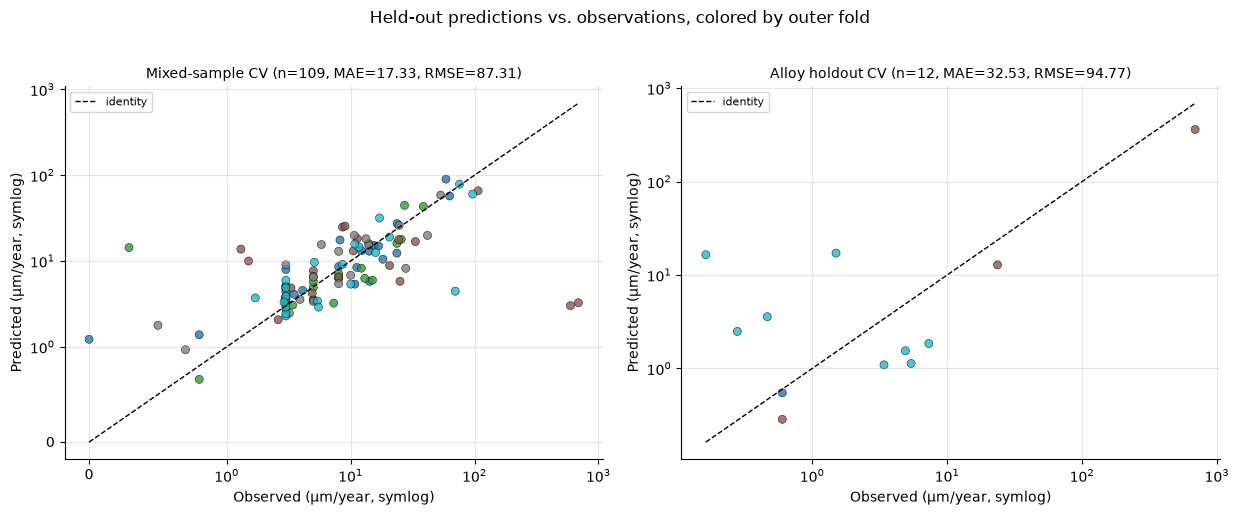

In [8]:
mixed_predictions = results["mixed"][1]
alloy_predictions = results["alloy"][1]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0))
labels = ["Mixed-sample CV", "Alloy holdout CV"]
for ax, predictions, label in zip(axes, [mixed_predictions, alloy_predictions], labels):
    summary = metrics(predictions.actual, predictions.prediction)
    ax.scatter(predictions.actual, predictions.prediction, s=34,
               c=predictions.fold, cmap="tab10", alpha=0.8, edgecolor="k", linewidth=0.4)
    limits = [min(predictions.actual.min(), predictions.prediction.min()),
              max(predictions.actual.max(), predictions.prediction.max())]
    ax.plot(limits, limits, "k--", linewidth=1, label="identity")
    ax.set_xscale("symlog", linthresh=1)
    ax.set_yscale("symlog", linthresh=1)
    ax.set(xlabel="Observed (μm/year, symlog)",
           ylabel="Predicted (μm/year, symlog)")
    ax.set_title(f"{label} (n={len(predictions)}, "
                 f"MAE={summary['mae']:.2f}, RMSE={summary['rmse']:.2f})", fontsize=10)
    ax.legend(fontsize=8)
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle("Held-out predictions vs. observations, colored by outer fold", y=1.02, fontsize=12)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "parity_plots.png", dpi=160, bbox_inches="tight")
plt.show()

### Figure: prediction intervals

Each vertical line is the 95% prediction band for one held-out row. The line is symmetric in
model space and asymmetric on the original scale. Light blue points fall inside their band.
Red points fall outside. The title shows the observed coverage. Coverage near 95% is not a
guarantee.

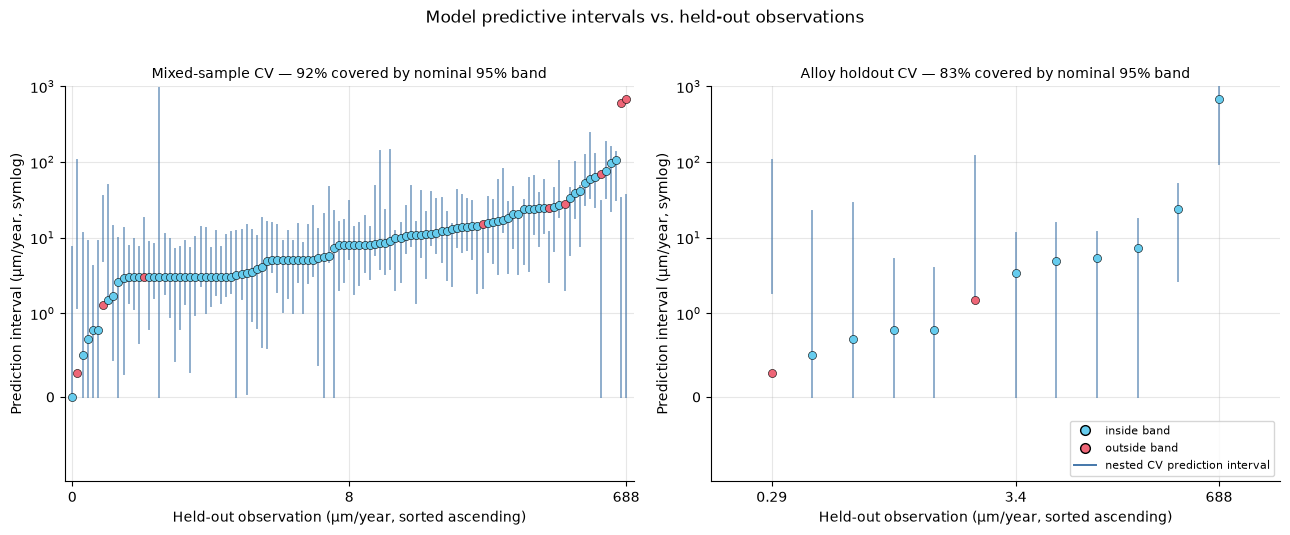

In [9]:
# Prediction intervals on a log target axis. Whiskers are symmetric in model space
# (ln(1+y) ± 1.96·σ) and asymmetric on the original scale.
fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.2))
for ax, predictions, label in zip(axes, [mixed_predictions, alloy_predictions],
                                  ["Mixed-sample", "Alloy holdout"]):
    order = predictions.sort_values("actual").reset_index(drop=True)
    positions = np.arange(len(order))
    covered = (order.actual >= order.lower_95) & (order.actual <= order.upper_95)
    coverage = float(covered.mean())

    for position, row in zip(positions, order.itertuples()):
        whisker_low = max(row.lower_95, 0.0)
        ax.plot([position, position], [whisker_low, row.upper_95],
                color="#4477aa", alpha=0.6, linewidth=1.4)
        facecolor = "#ee6677" if row.actual < whisker_low or row.actual > row.upper_95 else "#66ccee"
        ax.scatter(position, row.actual, s=34, color=facecolor, zorder=4,
                   edgecolor="k", linewidth=0.4)

    ax.set_xlim(positions[0] - 1.5, positions[-1] + 1.5)
    ax.set_ylim(-1, 1000)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_xticks(positions[[0, len(order) // 2, len(order) - 1]])
    ax.set_xticklabels([f"{value:g}" for value in order.actual.iloc[[0, len(order) // 2, len(order) - 1]]])
    ax.set(xlabel="Held-out observation (μm/year, sorted ascending)",
           ylabel="Prediction interval (μm/year, symlog)")
    ax.set_title(f"{label} CV — {coverage:.0%} covered by nominal 95% band", fontsize=10)
legend_handles = [Line2D([], [], marker="o", linestyle="", color="#66ccee",
                         markeredgecolor="k", markersize=7, label="inside band"),
                  Line2D([], [], marker="o", linestyle="", color="#ee6677",
                         markeredgecolor="k", markersize=7, label="outside band"),
                  Line2D([], [], color="#4477aa", linewidth=1.4, label="nested CV prediction interval")]
axes[1].legend(handles=legend_handles, fontsize=8, loc="lower right")
fig.suptitle("Model predictive intervals vs. held-out observations", y=1.02, fontsize=12)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "prediction_intervals.png", dpi=160, bbox_inches="tight")
plt.show()

### Figure: fold errors and residuals

The left plot shows the outer-fold RMSE. A large bar marks a difficult fold. The right plot
shows residual against observed corrosion rate. A large negative residual means the model
under-predicts a fast-corroding row.

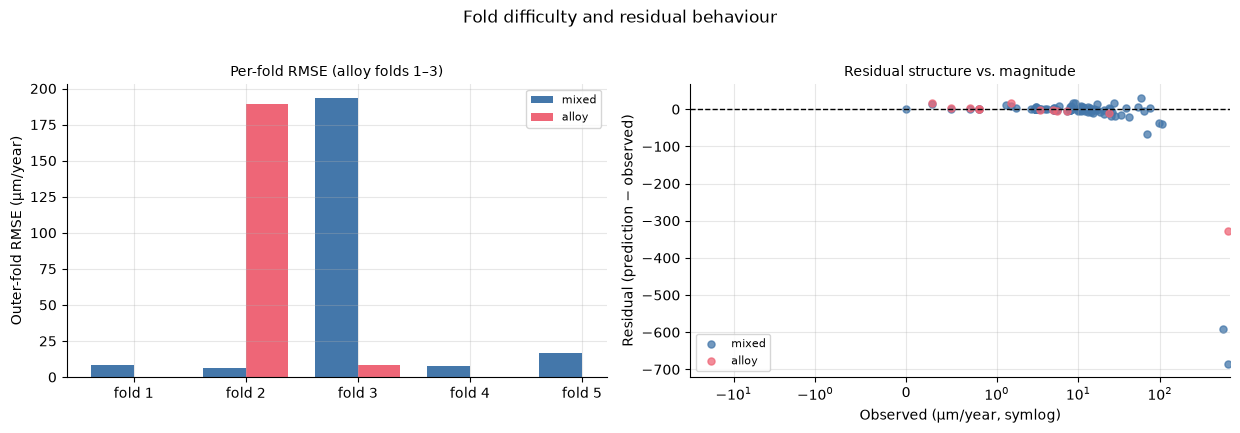

In [10]:
fold_table = pd.concat([results[name][0] for name in results])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
width = 0.38
positions = np.arange(len(results["mixed"][0]))
axes[0].bar(positions - width / 2, results["mixed"][0]["rmse"], width,
            color="#4477aa", label="mixed")
alloy_folds = results["alloy"][0]
if len(alloy_folds):
    axes[0].bar(positions[:len(alloy_folds)] + width / 2, alloy_folds["rmse"], width,
                color="#ee6677", label="alloy")
axes[0].set_xticks(positions)
axes[0].set_xticklabels([f"fold {i + 1}" for i in positions])
axes[0].set_ylabel("Outer-fold RMSE (μm/year)")
axes[0].set_title("Per-fold RMSE (alloy folds 1–3)", fontsize=10)
axes[0].legend(fontsize=8)

for regime, color in [("mixed", "#4477aa"), ("alloy", "#ee6677")]:
    if regime in results:
        predictions = results[regime][1]
        axes[1].scatter(predictions.actual, predictions.prediction - predictions.actual,
                        s=26, alpha=0.75, color=color, label=regime)
axes[1].axhline(0, color="k", linewidth=1, linestyle="--")
axes[1].set_xscale("symlog", linthresh=1)
axes[1].set(xlabel="Observed (μm/year, symlog)", ylabel="Residual (prediction − observed)")
axes[1].set_title("Residual structure vs. magnitude", fontsize=10)
axes[1].legend(fontsize=8)
fig.suptitle("Fold difficulty and residual behaviour", y=1.02, fontsize=12)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "folds_and_residuals.png", dpi=160, bbox_inches="tight")
plt.show()

### Figure: residual patterns against conditions

The left plot shows residual against temperature. The right plot shows residual against
exposure time. A visible trend shows a condition variable that the model did not capture.
A flat cloud around zero shows no clear pattern.

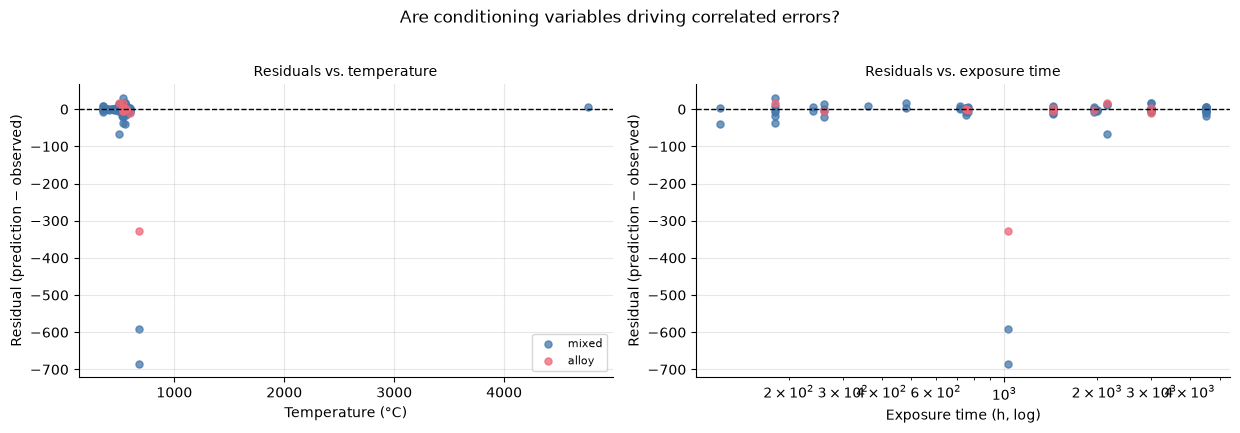

In [11]:
# Residuals against the physical drivers, colored by regime.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
for regime, color in [("mixed", "#4477aa"), ("alloy", "#ee6677")]:
    if regime not in results:
        continue
    predictions = results[regime][1].merge(
        data[["temperature_c", "exposure_time_h"]].reset_index(names="source_row"),
        on="source_row", how="left")
    axes[0].scatter(predictions.temperature_c, predictions.prediction - predictions.actual,
                    s=26, alpha=0.75, color=color, label=regime)
    axes[1].scatter(predictions.exposure_time_h, predictions.prediction - predictions.actual,
                    s=26, alpha=0.75, color=color, label=regime)
axes[0].axhline(0, color="k", linewidth=1, linestyle="--")
axes[1].axhline(0, color="k", linewidth=1, linestyle="--")
axes[1].set_xscale("log")
axes[0].set(xlabel="Temperature (°C)", ylabel="Residual (prediction − observed)")
axes[1].set(xlabel="Exposure time (h, log)", ylabel="Residual (prediction − observed)")
axes[0].set_title("Residuals vs. temperature", fontsize=10)
axes[1].set_title("Residuals vs. exposure time", fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle("Are conditioning variables driving correlated errors?", y=1.02, fontsize=12)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "residuals_vs_conditions.png", dpi=160, bbox_inches="tight")
plt.show()

### Figure: kernel grid diagnostics

The left plots show the inner RMSE for each of the nine candidates. Similar scores across
candidates show a stable optimum in the search. The right plot counts the folds that select
each optimized kernel. Stable selection shows reliable optimization.

Selected kernel configurations:
regime  selected_base  selected_length_init  count
 alloy Matern(nu=1.5)                   1.0      1
 alloy Matern(nu=1.5)                  10.0      1
 alloy            RBF                  10.0      1
 mixed Matern(nu=1.5)                   0.1      1
 mixed Matern(nu=1.5)                   1.0      1
 mixed Matern(nu=1.5)                  10.0      1
 mixed            RBF                  10.0      2


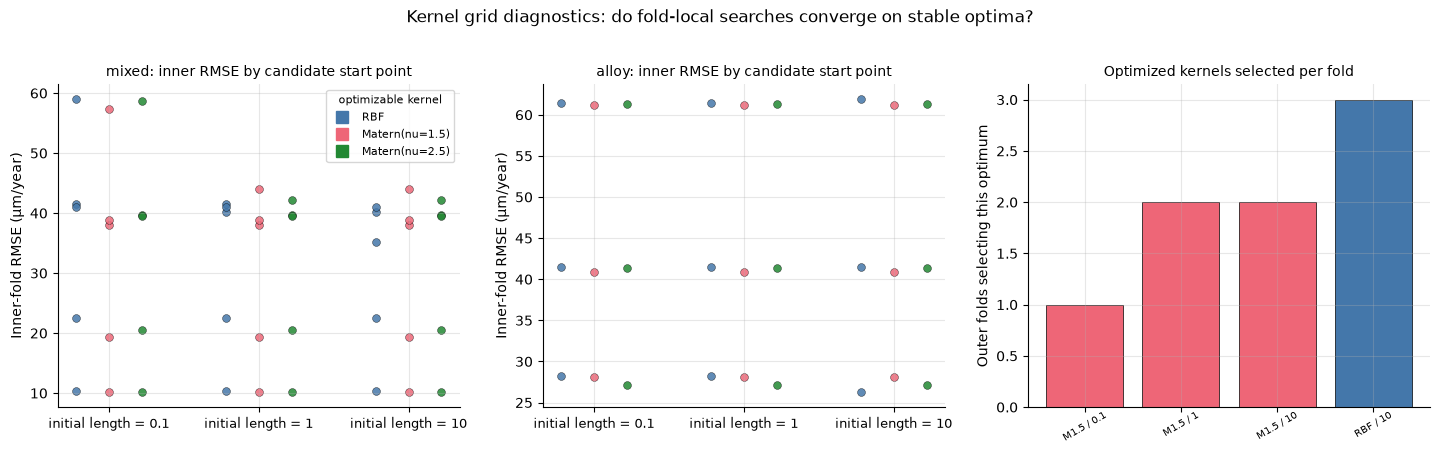

In [12]:
grid_table = pd.concat([results[name][2] for name in results], ignore_index=True)
selected = pd.concat([results[name][0] for name in results], ignore_index=True)
colors = {"RBF": "#4477aa", "Matern(nu=1.5)": "#ee6677", "Matern(nu=2.5)": "#228833"}

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))

selection_counts = (selected
                    .groupby(["regime", "selected_base", "selected_length_init"])
                    .size().reset_index(name="count"))
print("Selected kernel configurations:")
print(selection_counts.to_string(index=False))

for ax, regime in zip(axes[:2], ["mixed", "alloy"]):
    subset = grid_table[grid_table.regime == regime]
    for length_index, length in enumerate(KERNEL_LENGTH_INITS):
        for base_index, base in enumerate(KERNEL_BASE_NAMES):
            candidate = length_index * 3 + base_index
            scores = subset.loc[subset.candidate == candidate, "inner_rmse"]
            position = length_index + (base_index - 1) * 0.22
            ax.scatter(np.full(len(scores), position), scores, s=32,
                       color=colors[base], alpha=0.85,
                       edgecolor="k", linewidth=0.3)
    ax.set_xticks(range(len(KERNEL_LENGTH_INITS)))
    ax.set_xticklabels([f"initial length = {length:g}" for length in KERNEL_LENGTH_INITS], fontsize=9)
    ax.set_ylabel("Inner-fold RMSE (μm/year)")
    ax.set_title(f"{regime}: inner RMSE by candidate start point", fontsize=10)

kernel_panel = (selected.groupby(["selected_base", "selected_length_init"]).size()
                .reset_index(name="count"))
axes[2].bar(np.arange(len(kernel_panel)), kernel_panel["count"],
            color=[colors[base] for base in kernel_panel.selected_base],
            edgecolor="k", linewidth=0.5)
axes[2].set_xticks(np.arange(len(kernel_panel)))
def short_kernel(base, length):
    return f"{base.replace('Matern(nu=', 'M').replace(')', '')} / {length:g}"


axes[2].set_xticks(np.arange(len(kernel_panel)))
axes[2].set_xticklabels([short_kernel(base, length)
                         for base, length in zip(kernel_panel.selected_base,
                                                 kernel_panel.selected_length_init)],
                        fontsize=7, rotation=30)
axes[2].tick_params(axis="x", pad=-1)
axes[2].set_ylabel("Outer folds selecting this optimum")
axes[2].set_title("Optimized kernels selected per fold", fontsize=10)
legend_handles = [Line2D([], [], marker="s", linestyle="", color=color, markersize=8, label=base)
                  for base, color in colors.items()]
axes[0].legend(handles=legend_handles, fontsize=8, title="optimizable kernel", title_fontsize=8)
fig.suptitle("Kernel grid diagnostics: do fold-local searches converge on stable optima?",
             y=1.02, fontsize=12)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "kernel_selection.png", dpi=160, bbox_inches="tight")
plt.show()

### Figure: alloy isolation ranking

This plot shows the isolation score for each alloy group. The score is the smallest
composition distance to another group. Red bars mark the three held-out groups. A small
score shows a group close to other alloys in composition space.

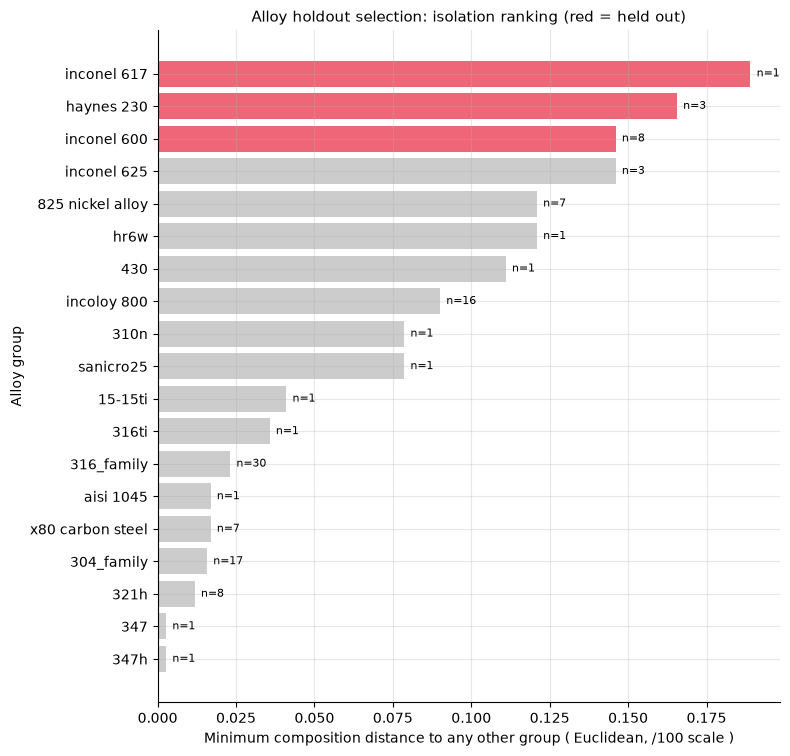

In [13]:
isolation = pd.read_csv(OUTPUT_DIR / "alloy_isolation.csv")
held_out = isolation.head(N_ALLOY_HOLDOUTS).alloy_group.tolist()
fig, ax = plt.subplots(figsize=(8.0, max(3.2, 0.34 * len(isolation) + 1.2)))
ordered = isolation.sort_values("isolation")
ax.barh(ordered.alloy_group, ordered.isolation,
        color=["#ee6677" if group in held_out else "#cccccc"
               for group in ordered.alloy_group])
ax.set_xlabel("Minimum composition distance to any other group ( Euclidean, /100 scale )")
ax.set_ylabel("Alloy group")
ax.set_title("Alloy holdout selection: isolation ranking (red = held out)", fontsize=11)
for index, (value, count) in enumerate(zip(ordered.isolation, ordered.n_test)):
    ax.text(value + 0.002, index, f"n={count}", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "alloy_isolation.png", dpi=160, bbox_inches="tight")
plt.show()

## Interpretation and next steps

Before you make reliability claims, do these steps:

1. Check the temperature 4765 °C against publication P008.
2. Review the alloy alias rules with the team. Agree on data rules, target rules, and folds
   across all models.
3. Run a raw-versus-log study with aligned targets and fold-local preprocessing.
4. Test the interval coverage and the sensitivity to the data approximations.

Caution: the selected-alloy experiment is not a leave-one-alloy-out study. The QML draft
uses 102 rows and publication holdouts. Its scores are not comparable to these scores.

## References

- Data provenance: `notebooks/data_cleaning.ipynb`
- GaussianProcessRegressor: https://scikit-learn.org/stable/modules/generated/sklearn.gaussian_process.GaussianProcessRegressor.html
- Gaussian process guide: https://scikit-learn.org/stable/modules/gaussian_process.html
- scikit-learn pipelines and nested CV: https://scikit-learn.org/stable/modules/cross_validation.html